In [68]:
import pandas as pd

df = pd.read_csv("../chordonomicon_spotifydump_join.csv.gz", compression='gzip')

In [46]:
df['chords'][0]

'<intro_1> Db Gb Db Eb7 Ab7 Db Ab7 Db Ab7 Db Gb Db Bbmin7 Eb7 Ab7 Db Ab7 Gb Ab7 Db <verse_1> Ab7 Db Ebmin7 Ab7 Ab Db Ab7 Db <verse_2> Ab7 Db Ebmin7 Ab7 Gb Eb7 Ab Db Eb7 Ab7 Db Ab7 Db Ab Bbmin F7 Bbmin F7 Bbmin Gb Eb7 Db Eb7 Ab7 Db <chorus_1> Ab7 Db Ab7 Db Gb Db Eb7 Ab7 Db Ab7 Db Ab Db <verse_3> Ab Db Ebmin7 Ab7 Ab Db Ab7 Db <verse_4> Ab7 Db Db7 Gb Eb7 Db Bb7 Eb7 Ab7 Db Ab7 Db Ab Bbmin F7 Bbmin F7 Bbmin Gb Eb7 Db Eb7 Ab7 Db <chorus_2> Ab7 Db Ab7 Db Gb Db Eb7 Ab7 Db'

In [69]:
df["unique_chords"] = df["chords"].apply(
    lambda chords: [
        chord
        for chord in dict.fromkeys(chords.split())
        if not chord.startswith("<")
    ]
)

In [70]:
df['year'] = pd.to_datetime(df['release_date'], errors='coerce').dt.year

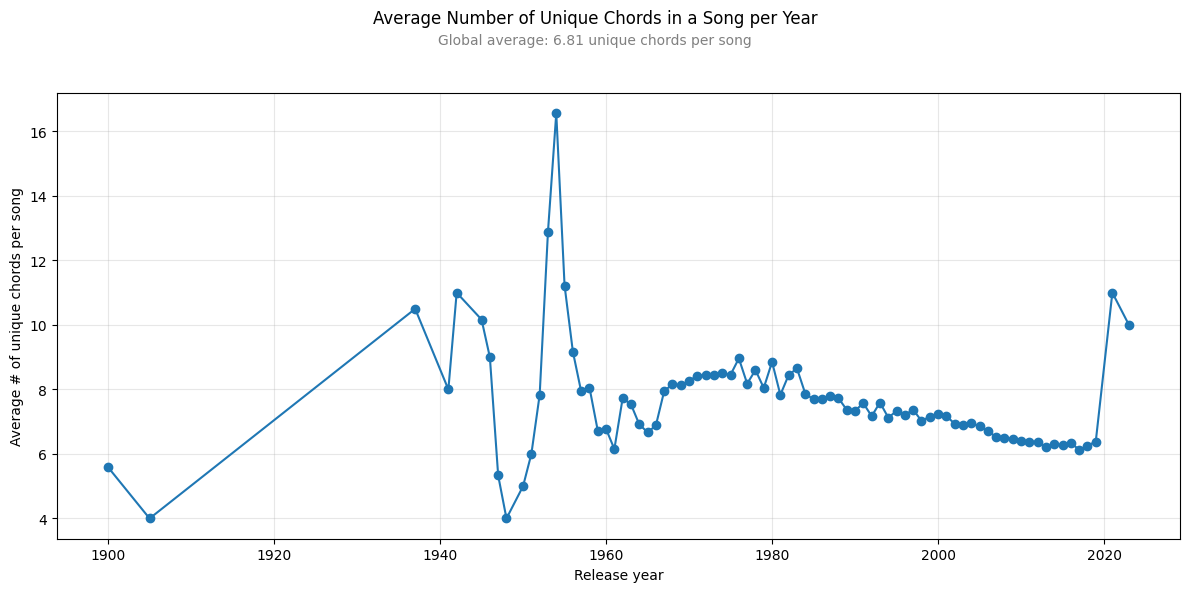

In [71]:
import matplotlib.pyplot as plt

df["unique_chord_count"] = df["unique_chords"].str.len()
global_average = df["unique_chord_count"].mean()

average_chords_by_year = (
    df.groupby("year")["unique_chord_count"]
    .mean()
)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(average_chords_by_year.index, average_chords_by_year.values, marker="o")

fig.suptitle("Average Number of Unique Chords in a Song per Year")
fig.text(
    0.5, 0.94,
    f"Global average: {global_average:.2f} unique chords per song",
    ha="center",
    va="top",
    fontsize=10,
    color="gray"
)

# Remove the ax.set_title(...) call
fig.tight_layout(rect=[0, 0, 1, 0.90])

ax.set(
    xlabel="Release year",
    ylabel="Average # of unique chords per song",
)
ax.grid(True, alpha=0.3)
fig.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig("../visualizations/unique_chords_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

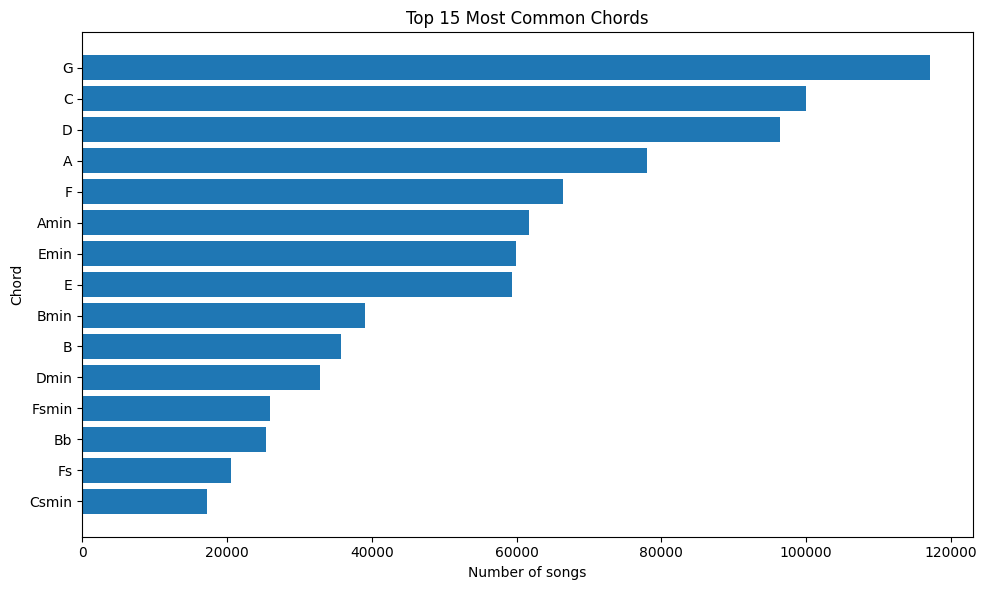

In [72]:
chord_counts = df["unique_chords"].explode().value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(chord_counts.index, chord_counts.values)
ax.invert_yaxis()

ax.set(
    title="Top 15 Most Common Chords",
    xlabel="Number of songs",
    ylabel="Chord",
)
fig.tight_layout()
fig.savefig("../visualizations/top_common_chords.png", dpi=150, bbox_inches="tight")
plt.show()

## Data Cleaning/Preprocessing with Final Dataset

In [100]:
import pandas as pd
import numpy as np

df = pd.read_csv("../chordonomicon_spotifydump_join.csv.gz", compression='gzip')

In [101]:
# Fix row that has a typo
df.loc[75915, "chords"] = df.loc[75915, "chords"].replace("sC", "Cs")

In [102]:
import re

SECTION_RE = re.compile(r"<[^>]+>")
ROOT_RE = re.compile(r"^([A-G](?:b|s(?!us))?)(.*)$")
SHARP_RE = re.compile(r"^([A-G])s(?!us)")

def prettify(chord: str) -> str:
    """Show Chordonomicon sharps as #, without rewriting sus chords."""
    def one(part: str) -> str:
        return SHARP_RE.sub(r"\1#", part)
        
    if "/" in chord:
        left, right = chord.split("/", 1)
        return f"{one(left)}/{one(right)}"
    return one(chord)

In [103]:
def prettify_chord_text(text):
    if not isinstance(text, str):
        return text

    return " ".join(
        token if SECTION_RE.fullmatch(token) else prettify(token)
        for token in text.split()
    )

df["chords"] = df["chords"].apply(prettify_chord_text)

In [104]:
# Extract unique chords
df["unique_chords"] = df["chords"].apply(
    lambda chords: [
        chord
        for chord in dict.fromkeys(chords.split())
        if not chord.startswith("<")
    ]
)

In [105]:
# Extract song year
df['year'] = pd.to_datetime(df['release_date'], errors='coerce').dt.year

In [106]:
df.drop(columns='Unnamed: 0', inplace=True)

In [107]:
df.loc[df['year'].isna(), 'year'] = df['release_date']

C:\Users\erik1\AppData\Local\Temp\ipykernel_4956\4292173079.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['2000' '1995' nan ... '1960' '1957' '1985']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[df['year'].isna(), 'year'] = df['release_date']


In [108]:
# Handling of rows that did not convert release_date to year with previous method
# 1. Create a mask identifying the unconvertible rows (ignoring existing NaNs)
mask = pd.to_numeric(df['year'], errors='coerce').isna() & df['year'].notna()

# 2. Extract the first 4 characters from 'release_date' for just those rows
# We use .astype(str) to ensure string slicing works safely
df.loc[mask, 'year'] = df.loc[mask, 'release_date'].astype(str).str[:4]

# 3. Now perform your original float conversion
df['year'] = df['year'].astype(float)

In [109]:
np.min(df['year']), np.max(df['year'])

(np.float64(1900.0), np.float64(2023.0))

In [110]:
# Extract chord roots
def extract_roots(chords):
    if isinstance(chords, str):
        chords = chords.strip().strip("[]").split(",")
    elif not isinstance(chords, (list, tuple)):
        return []

    roots = []
    for chord in chords:
        if not isinstance(chord, str):
            continue

        chord = chord.strip().strip("'\"")
        if chord:
            root = chord[:2] if len(chord) > 1 and chord[1] in ("b", "#") else chord[0]
            if root not in roots:
                roots.append(root)

    return roots

df["chord roots"] = df["unique_chords"].apply(extract_roots)

In [111]:
df.head()

,id,chords,release_date,genres,decade,rock_genre,artist_id,main_genre,spotify_song_id,spotify_artist_id,track,popularity,uri,db_artist_id,artist,unique_chords,year,chord roots
0,2,<intro_1> E D A/C# E D A/C# <verse_1> E D A/C#...,2003-01-01,'alternative metal' 'alternative rock' 'nu met...,2000.0,pop rock,artist_2,metal,2ffJZ2r8HxI5DHcmf3BO6c,694QW15WkebjcrWgQHzRYF,I Want To Die A Beautiful Death,12.0,spotify:track:2ffJZ2r8HxI5DHcmf3BO6c,694QW15WkebjcrWgQHzRYF,Everclear,"[E, D, A/C#, A, C, G]",2003.0,"[E, D, A, C, G]"
1,3,<intro_1> C#min <verse_1> A C#min A C#min A C#...,2003-01-01,'alternative metal' 'canadian rock' 'funk meta...,2000.0,canadian rock,artist_3,metal,5KiY8SZEnvCPyIEkFGRR3y,0niJkG4tKkne3zwr7I8n9n,Sad Exchange,28.0,spotify:track:5KiY8SZEnvCPyIEkFGRR3y,0niJkG4tKkne3zwr7I8n9n,Finger Eleven,"[C#min, A, B, F#min, D#min, G#min, C#]",2003.0,"[C#, A, B, F#, D#, G#]"
2,13,<intro_1> D G D G D G D G D G D Bb C D G D Bb ...,2009-11-13,'australian alternative rock' 'australian rock',2000.0,australian alternative rock,artist_10,rock,3ouHmB2wtv5CzbsWlAGZzq,6LBCQo20ri3tsvbsWWLmr6,Iberian Dream,26.0,spotify:track:3ouHmB2wtv5CzbsWlAGZzq,6LBCQo20ri3tsvbsWWLmr6,Powderfinger,"[D, G, Bb, C, A]",2009.0,"[D, G, Bb, C, A]"
3,14,<intro_1> E G D A <verse_1> D A D A D A D A <c...,2011-09-20,'comic',2010.0,NaN,artist_11,NaN,3uKv45soturBZVumfsXoag,292sg99iIOc93zcd30r4Oz,Glasses,29.0,spotify:track:3uKv45soturBZVumfsXoag,292sg99iIOc93zcd30r4Oz,Jonathan Coulton,"[E, G, D, A, Bmin]",2011.0,"[E, G, D, A, B]"
4,16,<intro_1> D F C D F C D F C D F C D <verse_1> ...,2000,'art punk' 'permanent wave' 'protopunk' 'singe...,1990.0,NaN,artist_13,punk,2YNNsFj1otPsgN6nQus2So,0vYkHhJ48Bs3jWcvZXvOrP,One Voice,11.0,spotify:track:2YNNsFj1otPsgN6nQus2So,0vYkHhJ48Bs3jWcvZXvOrP,Patti Smith,"[D, F, C, Emin, G, A, Bb, C/E]",2000.0,"[D, F, C, E, G, A, Bb]"


In [112]:
df.to_csv(
    "chordonomicon_transformed.csv.gz",
    index=False,
    compression="gzip",
)